In [1]:

import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
"gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})


from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, whoami
login(token=UserSecretsClient().get_secret("HF_TOKEN"))
print("Logged in to Hugging Face as:", whoami()["name"])

{'commit': '', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'gpu': 'Tesla T4', 'seed': 266}
Logged in to Hugging Face as: sadaffatimaeee


In [2]:

import io, json, os, hashlib
from datasets import load_dataset, Image as HFImage
from PIL import Image, ImageOps

DATASET = "lambdalabs/naruto-blip-captions"
raw = load_dataset(DATASET, split="train").cast_column("image", HFImage(decode=False))

good, seen = [], set()
n_corrupt = n_dup = 0
for r in raw:
    try:
        b = r["image"]["bytes"] or open(r["image"]["path"], "rb").read()
        im = Image.open(io.BytesIO(b)); im.load(); im = im.convert("RGB")
        if min(im.size) < 64 or not str(r["text"]).strip():
            raise ValueError("too small or empty caption")
    except Exception:
        n_corrupt += 1
        continue
    h = hashlib.md5(im.resize((64, 64)).tobytes()).hexdigest()   # same thumbnail = duplicate
    if h in seen:
        n_dup += 1
        continue
    seen.add(h)
    good.append((im, str(r["text"]).strip()))
print(f"loaded {len(raw)} | corrupted/unreadable removed: {n_corrupt} | duplicates removed: {n_dup} | kept: {len(good)}")

rng = random.Random(SEED)
idx = list(range(len(good))); rng.shuffle(idx)
n_test = round(0.10 * len(good))
splits = {"test": idx[:n_test], "train": idx[n_test:]}

for name, ids in splits.items():
    d = f"/kaggle/working/data/{name}"
    os.makedirs(d, exist_ok=True)
    with open(f"{d}/metadata.jsonl", "w") as f:
        for k, i in enumerate(ids):
            im, cap = good[i]
            fn = f"{name}_{k:04d}.png"
            ImageOps.fit(im, (512, 512), Image.Resampling.BICUBIC).save(f"{d}/{fn}")
            f.write(json.dumps({"file_name": fn, "text": cap}) + "\n")
    print(f"{name}: {len(ids)} images saved to {d}")

sizes = [im.size for im, _ in good]
caps = [c for _, c in good]
print("original sizes (most common):", max(set(sizes), key=sizes.count),
      "| mean caption length (words):", round(sum(len(c.split()) for c in caps) / len(caps), 1))
print("example captions:", caps[:3])

README.md:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/897 [00:00<?, ?B/s]

data/train-00000-of-00002-12944970063701(…): reconstructing file:   0%|          |  0.00B /  344MB            

data/train-00000-of-00002-12944970063701(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-cefa2f480689f1(…): reconstructing file:   0%|          |  0.00B /  357MB            

data/train-00001-of-00002-cefa2f480689f1(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1221 [00:00<?, ? examples/s]

loaded 1221 | corrupted/unreadable removed: 0 | duplicates removed: 0 | kept: 1221
test: 122 images saved to /kaggle/working/data/test
train: 1099 images saved to /kaggle/working/data/train
original sizes (most common): (1080, 1080) | mean caption length (words): 8.9
example captions: ['a man with dark hair and brown eyes', 'a man in a hoodie with a fire in the background', 'a man with a red hair and a black shirt']


In [3]:

import csv, re
test_caps = sorted({json.loads(l)["text"] for l in open("/kaggle/working/data/test/metadata.jsonl")})
SAFE = re.compile(r"\b(bath|bathtub|naked|nude|bed|shower|underwear)\b", re.I)
in_domain = random.Random(SEED).sample([c for c in test_caps if not SAFE.search(c)], 10)  # 10 in-domain, test captions, NSFW-prone ones excluded
out_domain = [                                                  # 5 out-of-domain
    "a red sports car parked on a city street at night",
    "a bowl of fruit on a wooden kitchen table",
    "a lighthouse on a rocky coast at sunset",
    "a golden retriever running on a beach",
    "a modern glass skyscraper under a blue sky",
]
compositional = [                                               # 5 compositional
    "two characters, one in red and one in blue",
    "a boy with yellow hair standing to the left of a girl with pink hair",
    "three ninjas in a row, the middle one wearing an orange jacket",
    "a man with white hair holding a red umbrella in the rain",
    "a girl in a green dress next to a boy in a black hoodie",
]
prompts = [("in_domain", p) for p in in_domain] + [("out_of_domain", p) for p in out_domain] \
        + [("compositional", p) for p in compositional]
with open("/kaggle/working/p2_prompts.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["pid", "type", "prompt"])
    for i, (t, p) in enumerate(prompts, 1):
        w.writerow([f"P{i:02d}", t, p])
print(open("/kaggle/working/p2_prompts.csv").read())

pid,type,prompt
P01,in_domain,a group of people in military uniforms and helmets
P02,in_domain,a man with red hair and green eyes
P03,in_domain,a woman with a sword in her hand
P04,in_domain,a woman with a gun in her hand
P05,in_domain,a man in a black and white outfit
P06,in_domain,a man with long blonde hair and a black shirt
P07,in_domain,a woman with long hair and a sword
P08,in_domain,a man in a hoodie with a fire in the background
P09,in_domain,a man with sunglasses and a hat on
P10,in_domain,a man with a mohawk in his hair
P11,out_of_domain,a red sports car parked on a city street at night
P12,out_of_domain,a bowl of fruit on a wooden kitchen table
P13,out_of_domain,a lighthouse on a rocky coast at sunset
P14,out_of_domain,a golden retriever running on a beach
P15,out_of_domain,a modern glass skyscraper under a blue sky
P16,compositional,"two characters, one in red and one in blue"
P17,compositional,a boy with yellow hair standing to the left of a girl with pink hair
P18,composi

In [4]:
!pip install -q -U diffusers peft && pip uninstall -y -q torchao
# Task 2.2 - training setup + one function that trains a LoRA run and records the table fields
SMOKE = False                     # True = quick 10-step test in the draft; False only for the final Save & Run All
STEPS = 10 if SMOKE else 750      # same step budget for both runs
BASE = "stable-diffusion-v1-5/stable-diffusion-v1-5"
LR, BATCH, ACCUM = 1e-4, 1, 4

import os, time, threading, subprocess, json
import diffusers
from safetensors.torch import load_file
tag = "main" if "dev" in diffusers.__version__ else f"v{diffusers.__version__}"
subprocess.run(["wget", "-q", "-O", "/kaggle/working/train_lora.py",
                f"https://raw.githubusercontent.com/huggingface/diffusers/{tag}/examples/text_to_image/train_text_to_image_lora.py"], check=True)
print("diffusers", diffusers.__version__, "| training script from", tag)

def gpu_mem_of(pid):
    """GPU memory (MiB) used by one process, from nvidia-smi."""
    r = subprocess.run(["nvidia-smi", "--query-compute-apps=pid,used_memory", "--format=csv,noheader,nounits"],
                       capture_output=True, text=True)
    for line in r.stdout.strip().splitlines():
        p, m = [x.strip() for x in line.split(",")]
        if p == str(pid):
            return int(m)
    return 0

def train_run(name, rank):
    out = f"/kaggle/working/{name}"
    cmd = ["python", "/kaggle/working/train_lora.py",
           f"--pretrained_model_name_or_path={BASE}", "--train_data_dir=/kaggle/working/data/train",
           "--resolution=512", "--center_crop", "--random_flip",
           f"--train_batch_size={BATCH}", f"--gradient_accumulation_steps={ACCUM}", "--gradient_checkpointing",
           f"--max_train_steps={STEPS}", f"--learning_rate={LR}", "--lr_scheduler=constant", "--lr_warmup_steps=0",
           f"--rank={rank}", "--mixed_precision=fp16", f"--seed={SEED}", "--checkpointing_steps=100000",
           "--dataloader_num_workers=2", f"--output_dir={out}"]
    t0 = time.time()
    proc = subprocess.Popen(cmd, env={**os.environ, "CUDA_VISIBLE_DEVICES": "0"},     # one GPU only
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    peak, log = [0], []
    def poll():
        while proc.poll() is None:
            peak[0] = max(peak[0], gpu_mem_of(proc.pid))
            time.sleep(2)
    threading.Thread(target=poll, daemon=True).start()
    for line in proc.stdout:
        log.append(line)
    proc.wait()
    secs = time.time() - t0
    if proc.returncode != 0:
        print("".join(log[-60:]))
        raise RuntimeError(f"{name} failed")
    w = load_file(f"{out}/pytorch_lora_weights.safetensors")
    row = {"run": name, "method": f"LoRA rank {rank}", "trainable params": sum(t.numel() for t in w.values()),
           "learning rate": LR, "steps": STEPS, "batch size": f"{BATCH} x {ACCUM} grad-accum = {BATCH * ACCUM}",
           "peak GPU memory (GB)": round(peak[0] / 1024, 2), "training time (min)": round(secs / 60, 1),
           "GPU-hours": round(secs / 3600, 3)}
    json.dump(row, open(f"{out}/train_stats.json", "w"))
    print(row)
    return row

if SMOKE:
    train_run("lora_smoke", rank=4)      # quick test only - checks that everything works
else:
    for name, rank in [("run1_lora_r4", 4), ("run2_lora_r16", 16)]:   # same data, steps and settings; only the rank differs
        train_run(name, rank)


diffusers 0.42.1 | training script from v0.42.1
{'run': 'run1_lora_r4', 'method': 'LoRA rank 4', 'trainable params': 797184, 'learning rate': 0.0001, 'steps': 750, 'batch size': '1 x 4 grad-accum = 4', 'peak GPU memory (GB)': 4.26, 'training time (min)': 24.8, 'GPU-hours': 0.413}
{'run': 'run2_lora_r16', 'method': 'LoRA rank 16', 'trainable params': 3188736, 'learning rate': 0.0001, 'steps': 750, 'batch size': '1 x 4 grad-accum = 4', 'peak GPU memory (GB)': 4.3, 'training time (min)': 23.5, 'GPU-hours': 0.391}


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


120 images | {'base': 40, 'run1_lora_r4': 40, 'run2_lora_r16': 40} | NSFW-flagged: 2 | minutes: 8.6
columns: base | run1 LoRA r4 | run2 LoRA r16   rows: ['P01', 'P03', 'P06', 'P08', 'P11', 'P14', 'P16', 'P17']


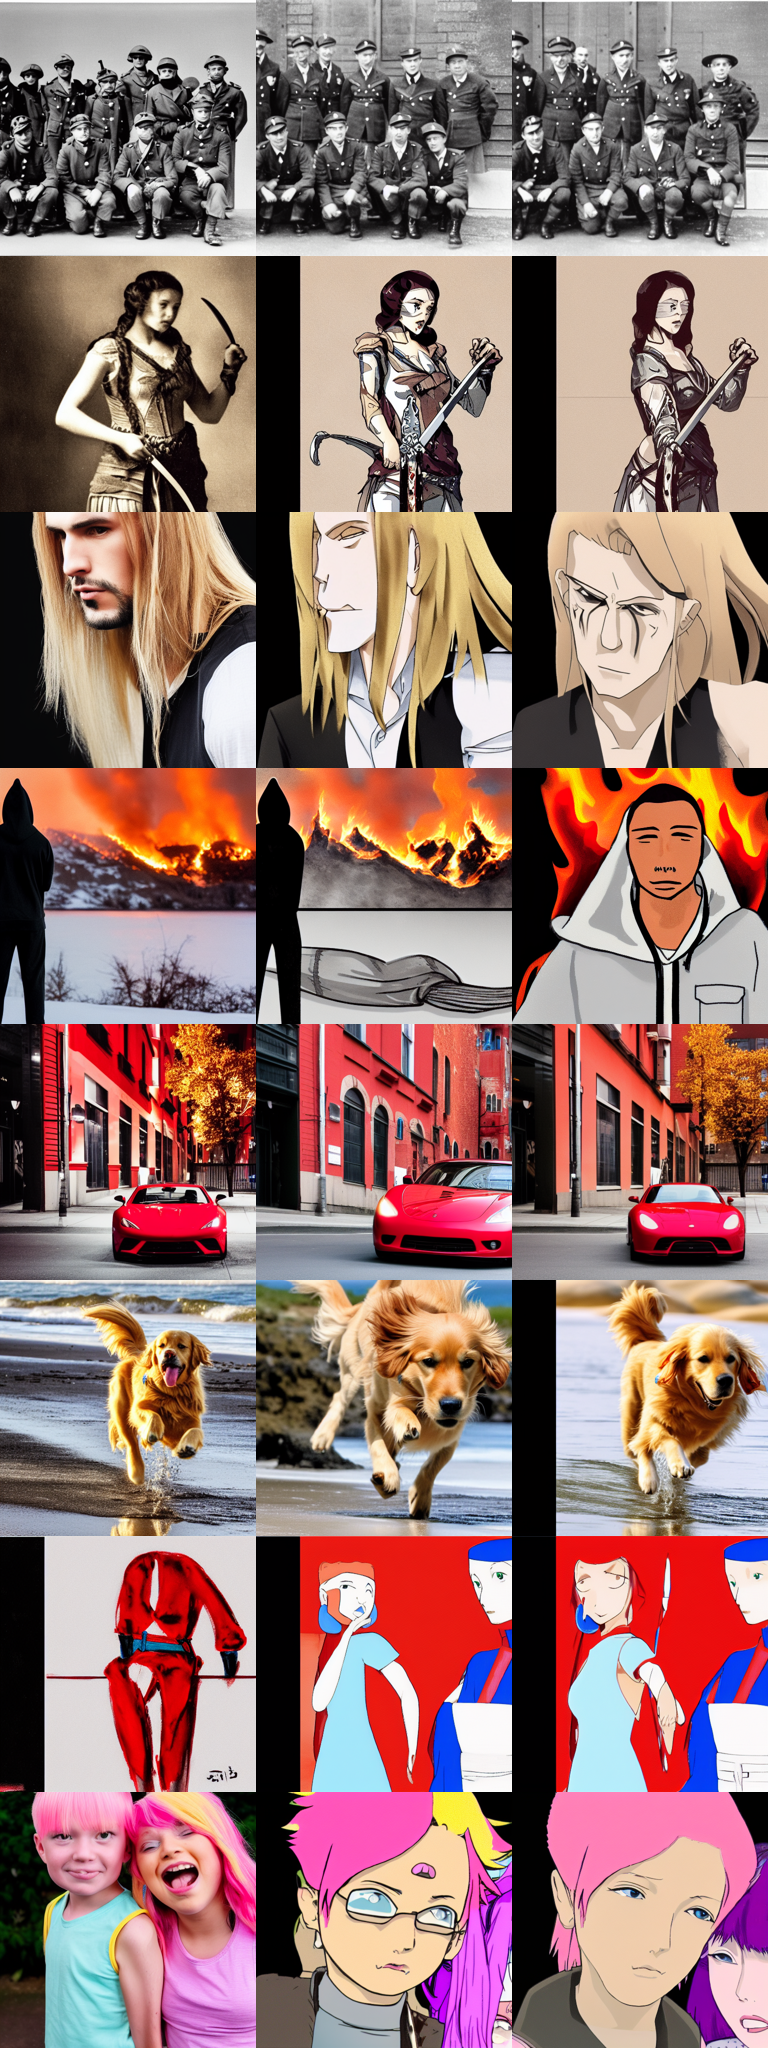

In [5]:

import pandas as pd
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
from PIL import Image
from IPython.display import display

P = pd.read_csv("/kaggle/working/p2_prompts.csv")
if SMOKE:
    P = P[P["pid"].isin(["P01", "P11"])]          
RUN_DIRS = {"base": None,
            "run1_lora_r4": "/kaggle/working/lora_smoke" if SMOKE else "/kaggle/working/run1_lora_r4",
            "run2_lora_r16": "/kaggle/working/lora_smoke" if SMOKE else "/kaggle/working/run2_lora_r16"}
GEN = dict(num_inference_steps=25, guidance_scale=7.5, height=512, width=512)   # same for every model

pipe = StableDiffusionPipeline.from_pretrained(BASE, torch_dtype=torch.float16).to("cuda")   
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

rows = []
t0 = time.time()
for model, lora in RUN_DIRS.items():
    pipe.unload_lora_weights()
    if lora:
        pipe.load_lora_weights(lora)
    os.makedirs(f"/kaggle/working/gen/{model}", exist_ok=True)
    for _, r in P.iterrows():
        for seed in (0, 1):
            out = pipe(r["prompt"], generator=torch.Generator("cuda").manual_seed(seed), **GEN)
            fn = f"gen/{model}/{r['pid']}_seed{seed}.png"
            out.images[0].save(f"/kaggle/working/{fn}")
            rows.append({"file": fn, "model": model, "pid": r["pid"], "type": r["type"], "prompt": r["prompt"],
                         "seed": seed, "nsfw_flagged": bool(out.nsfw_content_detected and out.nsfw_content_detected[0]),
                         "sampler": "DPMSolverMultistep", **GEN})
gen = pd.DataFrame(rows)
gen.to_csv("/kaggle/working/gen/metadata.csv", index=False)
print(len(gen), "images |", gen.groupby("model").size().to_dict(),
      "| NSFW-flagged:", int(gen["nsfw_flagged"].sum()), "| minutes:", round((time.time() - t0) / 60, 1))


GRID_PIDS = [p for p in ["P01", "P03", "P06", "P08", "P11", "P14", "P16", "P17"] if p in set(P["pid"])]
S = 256
grid = Image.new("RGB", (S * len(RUN_DIRS), S * len(GRID_PIDS)), "white")
for i, pid in enumerate(GRID_PIDS):
    for j, m in enumerate(RUN_DIRS):
        grid.paste(Image.open(f"/kaggle/working/gen/{m}/{pid}_seed0.png").resize((S, S)), (j * S, i * S))
grid.save("/kaggle/working/gen/grid_8_prompts.png")
print("columns: base | run1 LoRA r4 | run2 LoRA r16   rows:", GRID_PIDS)
display(grid)

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth




  0%|          | 0.00/233M [00:00<?, ?B/s]

  4%|▍         | 9.75M/233M [00:00<00:02, 102MB/s]

 11%|█▏        | 26.2M/233M [00:00<00:01, 144MB/s]

 19%|█▊        | 43.1M/233M [00:00<00:01, 158MB/s]

 25%|██▍       | 58.2M/233M [00:01<00:07, 25.7MB/s]

 30%|███       | 70.2M/233M [00:01<00:05, 34.1MB/s]

 36%|███▌      | 83.1M/233M [00:01<00:03, 44.9MB/s]

 42%|████▏     | 99.0M/233M [00:02<00:02, 60.9MB/s]

 49%|████▉     | 115M/233M [00:02<00:01, 77.4MB/s] 

 58%|█████▊    | 136M/233M [00:02<00:00, 103MB/s] 

 65%|██████▍   | 152M/233M [00:02<00:00, 117MB/s]

 72%|███████▏  | 168M/233M [00:02<00:00, 127MB/s]

 79%|███████▊  | 183M/233M [00:02<00:00, 136MB/s]

 86%|████████▌ | 200M/233M [00:02<00:00, 145MB/s]

 92%|█████████▏| 216M/233M [00:02<00:00, 136MB/s]

100%|██████████| 233M/233M [00:02<00:00, 84.8MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For la

PART 2 RESULTS TABLE (base vs run 1 vs run 2)
              KID in-domain (mean) KID std CLIP score (all) CLIP in_domain CLIP out_of_domain CLIP compositional LPIPS diversity trainable params peak GPU memory (GB) GPU-hours (training) NSFW-flagged
base                        0.1386  0.0117        32.220001      32.189999              32.16              32.34          0.7717                0                    -                  0.0            0
run1_lora_r4                0.0672  0.0093        31.200001          30.42              30.85              33.09          0.7801         797184.0                 4.26                0.413          1.0
run2_lora_r16               0.0389   0.008             30.9          30.32          32.009998          30.940001          0.7851        3188736.0                  4.3                0.391          1.0

TRAINING TABLE
                         run        method trainable params learning rate steps            batch size peak GPU memory (GB) training ti

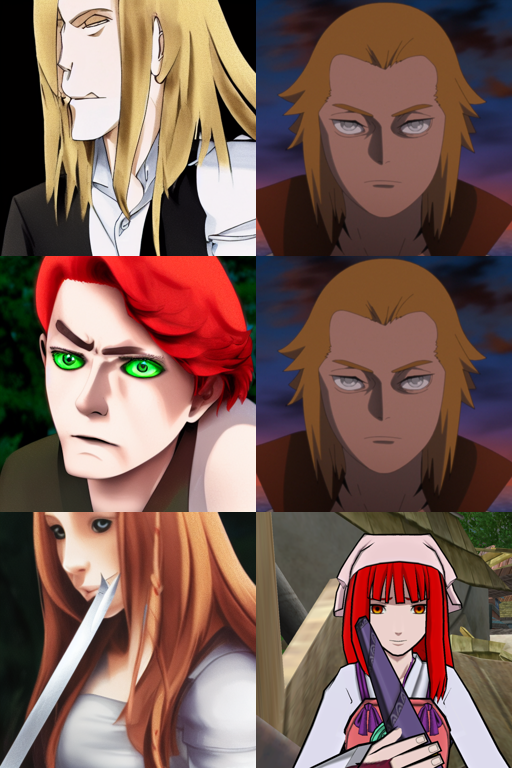


run2_lora_r16: highest CLIP similarity to any training image, per generated image: [0.504, 0.792, 0.737, 0.717, 0.86, 0.89, 0.749, 0.82, 0.869, 0.809]
  pair 1: P06 vs train_0361.png (similarity 0.890)
  pair 2: P09 vs train_0783.png (similarity 0.869)
  pair 3: P05 vs train_0646.png (similarity 0.860)
  left = generated, right = closest training image


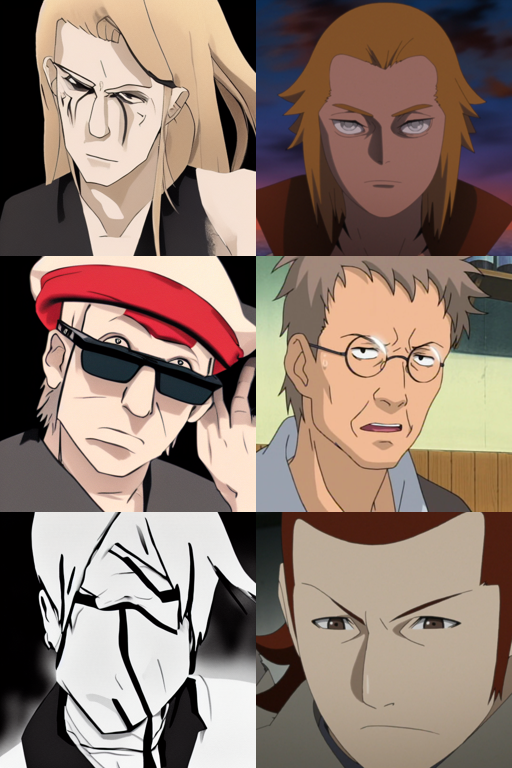

In [6]:
!pip install -q torchmetrics torch-fidelity lpips
# Task 2.4 - KID + CLIP score (primary), LPIPS diversity (secondary), GPU-hours (efficiency), memorization check
import glob, numpy as np, lpips
from torchmetrics.image.kid import KernelInceptionDistance
from transformers import CLIPModel, CLIPProcessor

del pipe; torch.cuda.empty_cache()                       # free the generation model
dev = "cuda"

def load(fn, size=None):
    im = Image.open(fn).convert("RGB")
    return im.resize((size, size), Image.Resampling.BICUBIC) if size else im

def to_u8(ims):
    return torch.stack([torch.from_numpy(np.array(i)).permute(2, 0, 1) for i in ims])

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch16").to(dev).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch16")

@torch.no_grad()
def img_emb(ims, bs=32):
    out = []
    for i in range(0, len(ims), bs):
        px = proc(images=ims[i:i + bs], return_tensors="pt")["pixel_values"].to(dev)
        e = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)
        out.append(e / e.norm(dim=-1, keepdim=True))
    return torch.cat(out)

@torch.no_grad()
def txt_emb(txts):
    t = proc(text=txts, return_tensors="pt", padding=True, truncation=True).to(dev)
    e = clip.text_projection(clip.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"]).pooler_output)
    return e / e.norm(dim=-1, keepdim=True)

lp = lpips.LPIPS(net="alex", verbose=False).to(dev)
def to_lp(im):
    return (torch.from_numpy(np.array(im)).permute(2, 0, 1).float() / 127.5 - 1).unsqueeze(0).to(dev)

gen = pd.read_csv("/kaggle/working/gen/metadata.csv")
test_u8 = to_u8([load(f, 299) for f in sorted(glob.glob("/kaggle/working/data/test/*.png"))])
stats = {m: json.load(open(f"{d}/train_stats.json")) for m, d in RUN_DIRS.items() if d}

results = {}
for model in RUN_DIRS:
    g = gen[gen["model"] == model]
    # CLIP score: 100 * cosine(image, prompt), averaged
    cs = (100 * (img_emb([load("/kaggle/working/" + f) for f in g["file"]]) * txt_emb(list(g["prompt"]))).sum(-1)
          .clamp(min=0)).cpu().numpy()
    # KID: in-domain generations vs the 122 test images
    ind = [load("/kaggle/working/" + f, 299) for f in g[g["type"] == "in_domain"]["file"]]
    kid = KernelInceptionDistance(subset_size=len(ind), subsets=50).to(dev)
    for i in range(0, len(test_u8), 32):
        kid.update(test_u8[i:i + 32].to(dev), real=True)
    kid.update(to_u8(ind).to(dev), real=False)
    torch.manual_seed(SEED)                               # KID samples random subsets - fix the seed
    km, ks = kid.compute()
    # LPIPS diversity: distance between seed 0 and seed 1 of each prompt
    with torch.no_grad():
        lps = [lp(to_lp(load(f"/kaggle/working/gen/{model}/{p}_seed0.png")),
                  to_lp(load(f"/kaggle/working/gen/{model}/{p}_seed1.png"))).item() for p in g["pid"].unique()]
    s = stats.get(model, {})
    results[model] = {
        "KID in-domain (mean)": round(km.item(), 4), "KID std": round(ks.item(), 4),
        "CLIP score (all)": round(cs.mean(), 2),
        **{f"CLIP {t}": round(cs[(g["type"] == t).values].mean(), 2) for t in ["in_domain", "out_of_domain", "compositional"] if (g["type"] == t).any()},
        "LPIPS diversity": round(float(np.mean(lps)), 4),
        "trainable params": s.get("trainable params", 0), "peak GPU memory (GB)": s.get("peak GPU memory (GB)", "-"),
        "GPU-hours (training)": s.get("GPU-hours", 0.0), "NSFW-flagged": int(g["nsfw_flagged"].sum())}

table = pd.DataFrame(results).T
print("PART 2 RESULTS TABLE (base vs run 1 vs run 2)")
print(table.to_string())
table.to_csv("/kaggle/working/p2_results_table.csv")
print("\nTRAINING TABLE")
print(pd.DataFrame(stats).T.to_string())

# Memorization check: 10 in-domain generations (seed 0) -> most similar training image by CLIP similarity
train_files = sorted(glob.glob("/kaggle/working/data/train/*.png"))
train_e = img_emb([load(f, 224) for f in train_files])
S = 256
for model in [m for m in RUN_DIRS if RUN_DIRS[m]]:
    g0 = gen[(gen["model"] == model) & (gen["type"] == "in_domain") & (gen["seed"] == 0)]
    best, idx = (img_emb([load("/kaggle/working/" + f) for f in g0["file"]]) @ train_e.T).max(1)
    print(f"\n{model}: highest CLIP similarity to any training image, per generated image:",
          [round(x, 3) for x in best.tolist()])
    top = best.argsort(descending=True)[:3].tolist()
    pairs = Image.new("RGB", (2 * S, S * len(top)), "white")
    for r, k in enumerate(top):
        pairs.paste(load("/kaggle/working/" + g0["file"].iloc[k], S), (0, r * S))
        pairs.paste(load(train_files[idx[k].item()], S), (S, r * S))
        print(f"  pair {r + 1}: {g0['pid'].iloc[k]} vs {os.path.basename(train_files[idx[k].item()])} "
              f"(similarity {best[k].item():.3f})")
    pairs.save(f"/kaggle/working/gen/memorization_{model}.png")
    print("  left = generated, right = closest training image")
    display(pairs)

In [7]:
# Task 2.2 / 2.3 - model cards + all generated images (with prompt, seed, model) to Hugging Face
from huggingface_hub import HfApi
api = HfApi()
USER = "sadaffatimaeee"
sfx = "-smoke-test" if SMOKE else ""                      # the quick test uploads to separate *-smoke-test repos

meta = gen.copy()
meta["file_name"] = meta["file"].str.replace("gen/", "", regex=False)
meta.drop(columns="file").to_csv("/kaggle/working/gen/metadata.csv", index=False)
ds_repo = f"{USER}/naruto-lora-generations{sfx}"
api.create_repo(ds_repo, repo_type="dataset", exist_ok=True)
api.upload_folder(folder_path="/kaggle/working/gen", repo_id=ds_repo, repo_type="dataset",
                  allow_patterns=["base/*", "run1_lora_r4/*", "run2_lora_r16/*", "metadata.csv"])
api.upload_file(path_or_fileobj="/kaggle/working/gen/grid_8_prompts.png", path_in_repo="grid_8_prompts.png",
                repo_id=ds_repo, repo_type="dataset")
print("images:", f"https://huggingface.co/datasets/{ds_repo}")

for name in ["run1_lora_r4", "run2_lora_r16"]:
    repo = f"{USER}/naruto-sd15-{name.replace('_', '-')}{sfx}"
    r, s = results[name], stats[name]
    card = f"""---
base_model: {BASE}
library_name: diffusers
tags: [lora, stable-diffusion, text-to-image, naruto]
license: other
---
# Naruto-style LoRA for Stable Diffusion 1.5 ({s['method']})

DATA 266 Lab 2, Part 2 - Pair_Programming_Team_16. Non-commercial research and teaching use only.

**Base model:** `{BASE}` (512x512). Only the UNet attention layers are adapted (LoRA); the text encoder is frozen.

**Data:** `{DATASET}`: {len(good)} captioned images after cleaning (0 corrupted, 0 duplicates removed),
split 90/10 with seed {SEED} ({len(splits['train'])} train / {len(splits['test'])} test), resized to 512x512.
Captions are short BLIP captions (about 9 words).

**Training:** diffusers `train_text_to_image_lora.py`, LoRA rank {s['method'].split()[-1]},
{s['trainable params']:,} trainable parameters, learning rate {s['learning rate']} (constant), {s['steps']} steps,
batch {s['batch size']}, fp16, gradient checkpointing, seed {SEED}, one Tesla T4.
Peak GPU memory {s['peak GPU memory (GB)']} GB, training time {s['training time (min)']} min ({s['GPU-hours']} GPU-hours).

**Results** (20 fixed prompts x seeds 0 and 1, DPM-Solver 25 steps, guidance 7.5):
KID vs test images (in-domain prompts) {r['KID in-domain (mean)']} +/- {r['KID std']};
CLIP score {r['CLIP score (all)']} (in-domain {r.get('CLIP in_domain', '-')}, out-of-domain {r.get('CLIP out_of_domain', '-')},
compositional {r.get('CLIP compositional', '-')}); LPIPS diversity between seeds {r['LPIPS diversity']}.
KID is noisy with this few images.

**Limitations:** narrow anime style; captions are short and generic and describe mostly male characters;
compositional prompts (colours, positions, counts) are often not followed; out-of-domain prompts drift into the anime style.

**License:** the training images show copyrighted Naruto characters, so this adapter is for non-commercial research only.
Generated images pass through the Stable Diffusion safety checker (NSFW filter). A memorization check
(closest training image by CLIP similarity) is in `memorization.png`.
"""
    api.create_repo(repo, exist_ok=True)
    api.upload_folder(folder_path=RUN_DIRS[name], repo_id=repo, allow_patterns=["*.safetensors", "*.json"])
    api.upload_file(path_or_fileobj=card.encode(), path_in_repo="README.md", repo_id=repo)
    api.upload_file(path_or_fileobj=f"/kaggle/working/gen/memorization_{name}.png", path_in_repo="memorization.png", repo_id=repo)
    print("model:", f"https://huggingface.co/{repo}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

images: https://huggingface.co/datasets/sadaffatimaeee/naruto-lora-generations


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

... (2 outputs left out)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

model: https://huggingface.co/sadaffatimaeee/naruto-sd15-run2-lora-r16
